In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '../data/wdc_data_full.json'

# Read the JSON dataset
df = pd.read_json(file_path)

# If the dataframe loaded as a single row (transposed), fix it to standard tabular format
if len(df) == 1:
    df = pd.DataFrame(df.iloc[0].to_dict())

print("Dataset loaded and fixed successfully!\n")

# Display the first 5 rows of the dataframe
display(df.head())

# Display general information about the dataset structure
print("\n--- Dataset Structure ---")
df.info()

Dataset loaded and fixed successfully!



,CategoryID,cluster_id,gtin,identifiers,nodeID,parent_NodeID,parent_schema.org_properties,relationToParent,schema.org_properties,url,CategoryName,desc,title,tokenmatch,pathlist_ids,pathlist_names
0,151,1554982,4713147158539,"[{'/mpn': '[nxm81eh034]'}, {'/gtin13': '[47131...",_:node33a393d77c979bd19c80e82fde5d34,<https://tweakers.net/pricewatch/366424/acer-a...,[{'/title': '[ acer aspire e1 522 65208g1tmnkk...,http://www.w3.org/1999/xhtml/microdata#item,[{'/name': '[ acer aspire e1 522 65208g1tmnkk ...,https://tweakers.net/pricewatch/366424/acer-as...,Notebooks,,acer aspire e1 522 65208g1tmnkk specificaties,True,"[2833, 150, 151]","[Computers & Electronics, Computers, Notebooks]"
6,151,1700753,4719072491413,"[{'/mpn': '[9s717b112207]'}, {'/gtin13': '[471...",_:node5559174e2b61f79ca7706d7276419,<https://www.overclockers.co.uk/msi-gs73vr-7rf...,[{'/title': '[ msi gs73vr 7rf 207uk nvidia gtx...,http://www.w3.org/1999/xhtml/microdata#item,"[{'/image': '[""https://www.overclockers.co.uk/...",https://www.overclockers.co.uk/msi-gs73vr-7rf-...,Notebooks,gs73vr 7rf stealth pro 4k 207uk 17 3 uhd ips ...,msi gs73vr 7rf 207uk nvidia gtx 1060 6gb gddr...,True,"[2833, 150, 151]","[Computers & Electronics, Computers, Notebooks]"
14,989,156063,5032037003773,"[{'/mpn': '[bx80532ke3066dsl6rr, bx80532ke306...",_:node71df169738ffa50ae5a1b57673cbc1,<https://icecat.us/us/p/intel/bx80532ke3066d/p...,[{'/title': '[ product data intel xeon process...,http://www.w3.org/1999/xhtml/microdata#item,[{'/name': '[ intel xeon processor 3 06 ghz 51...,https://icecat.us/us/p/intel/bx80532ke3066d/pr...,Processors,long product name intel xeon processor 3 06 g...,intel xeon processor 3 06 ghz 512k cache 533 ...,True,"[2833, 106, 2844, 989]","[Computers & Electronics, Computer Components,..."
15,377,97430,4960999577494,"[{'/mpn': '[cli521cyan]'}, {'/gtin13': '[49609...",_:nodefe451ab9804f9d4b5beccaf7deab0db,<http://www.inkredible.co.uk/canon-pixma-mp990...,[{'/title': '[ canon pixma mp990 ink cartridge...,http://www.w3.org/1999/xhtml/microdata#item,"[{'/image': '[""http://www.inkredible.co.uk/con...",http://www.inkredible.co.uk/canon-pixma-mp990-...,Ink Cartridges,oem cli 521 cyan 9ml with chip,canon pixma mp990 cyan genuine canon ink cart...,True,"[2833, 225, 373, 377]","[Computers & Electronics, Printers & Scanners,..."
16,1870,5506418,4895185604152,[{'/productID': '[4895185604152]'}],_:nodeed63364c16f9dc9e3aeb127523a42e6,<https://www.wupti.com/produkter/tv-og-hifi/ly...,[{'/title': '[ philips fidelio b5 12 wupti com...,http://www.w3.org/1999/xhtml/microdata#item,"[{'/name': '[ philips fidelio b5 12 ]'}, {'/pr...",https://www.wupti.com/produkter/tv-og-hifi/lyd...,Soundbar Speakers,210 w bluetooth surround 4 1 med nfc og bluet...,philips fidelio b5 12,True,"[2833, 1058, 1870]","[Computers & Electronics, Consumer Audio & Vid..."



--- Dataset Structure ---
<class 'pandas.core.frame.DataFrame'>
Index: 2984 entries, 0 to 18884
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   CategoryID                    2984 non-null   int64 
 1   cluster_id                    2984 non-null   int64 
 2   gtin                          2984 non-null   int64 
 3   identifiers                   2984 non-null   object
 4   nodeID                        2984 non-null   object
 5   parent_NodeID                 2984 non-null   object
 6   parent_schema.org_properties  2984 non-null   object
 7   relationToParent              2984 non-null   object
 8   schema.org_properties         2984 non-null   object
 9   url                           2984 non-null   object
 10  CategoryName                  2984 non-null   object
 11  desc                          2984 non-null   object
 12  title                         2984 non-null   object


C:\Users\user\AppData\Local\Temp\ipykernel_15136\3424309755.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')


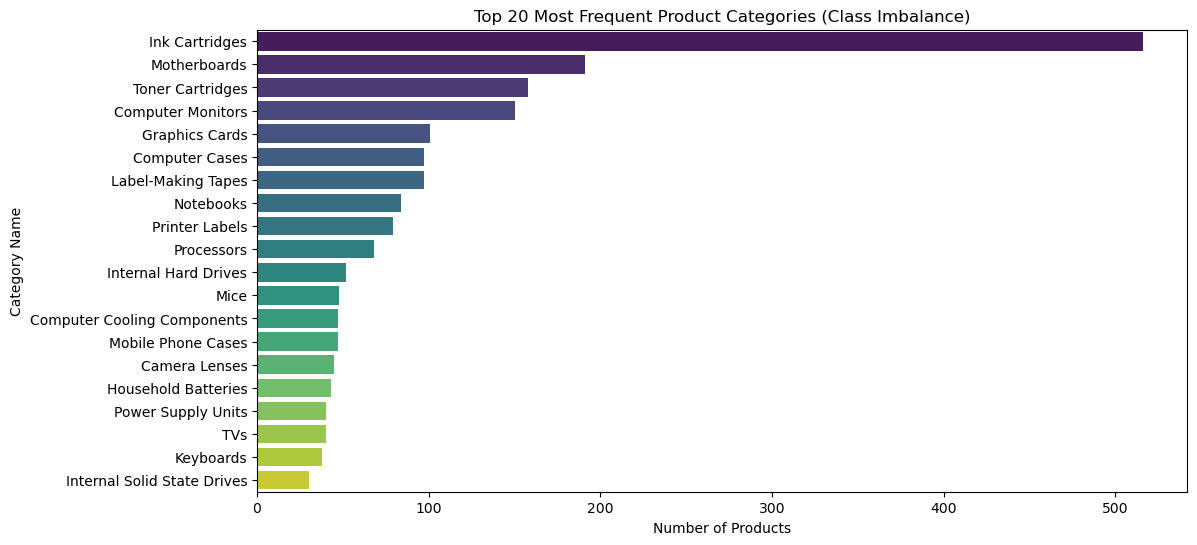

In [3]:
# CELL 2: Check Class Imbalance (Top 20 most frequent categories)
plt.figure(figsize=(12, 6))

# Count the occurrences of each category and take the top 20
top_categories = df['CategoryName'].value_counts().head(20)

# Create a horizontal bar chart
sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')
plt.title('Top 20 Most Frequent Product Categories (Class Imbalance)')
plt.xlabel('Number of Products')
plt.ylabel('Category Name')
plt.show()

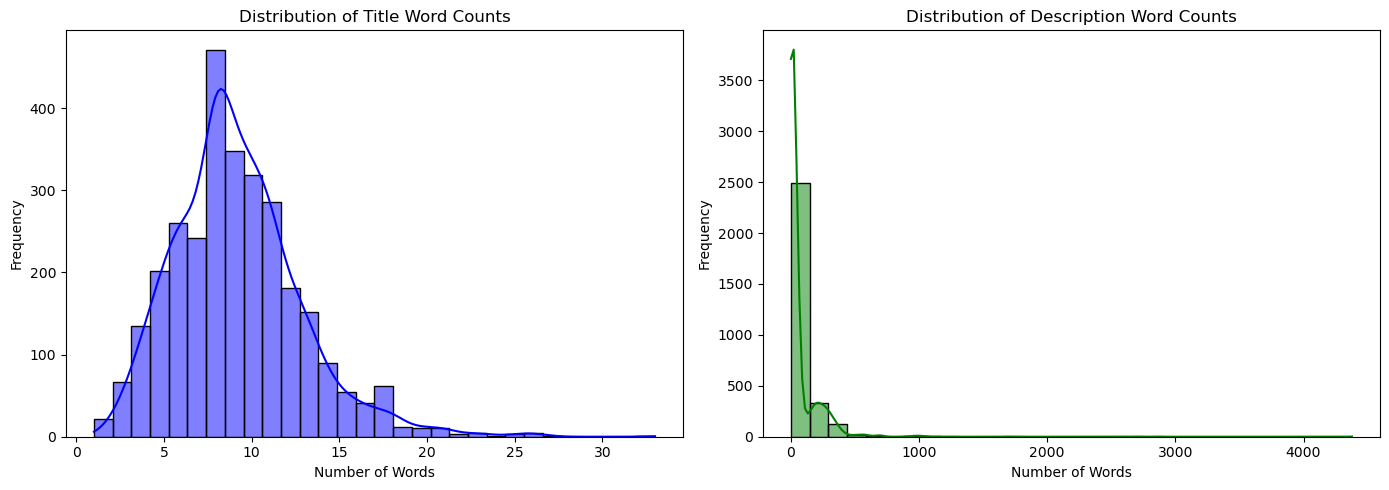

In [4]:
# CELL 3: Calculate and plot word counts for Title and Description
# Create new columns for word counts
df['title_word_count'] = df['title'].astype(str).apply(lambda x: len(x.split()))
df['desc_word_count'] = df['desc'].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(14, 5))

# Plot title length distribution
plt.subplot(1, 2, 1)
sns.histplot(df['title_word_count'], bins=30, color='blue', kde=True)
plt.title('Distribution of Title Word Counts')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

# Plot description length distribution
plt.subplot(1, 2, 2)
sns.histplot(df['desc_word_count'], bins=30, color='green', kde=True)
plt.title('Distribution of Description Word Counts')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [5]:
# CELL 4: Baseline 1 - TF-IDF + Logistic Regression
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# 1. Prepare the text data (Combine Title and Description, handle missing values)
df['text'] = df['title'].fillna('') + " " + df['desc'].fillna('')
X = df['text']
y = df['CategoryName']

# 2. Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Convert text to numerical features using TF-IDF
# Limiting to 5000 features to keep it efficient for the baseline
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# 4. Train the Logistic Regression model
print("Training Logistic Regression model. This might take a few seconds...")
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

# 5. Evaluate the model on the test set
print("Evaluating model performance...\n")
y_pred = model.predict(X_test_tfidf)

# Print the classification report (Accuracy, Precision, Recall, F1-Score)
print(classification_report(y_test, y_pred, zero_division=0))

Training Logistic Regression model. This might take a few seconds...
Evaluating model performance...

                                       precision    recall  f1-score   support

                3D Printing Materials       1.00      1.00      1.00         5
                Action Sports Cameras       0.00      0.00      0.00         1
          Antivirus Security Software       0.00      0.00      0.00         1
                          Audio Cards       0.00      0.00      0.00         1
                         Backpack PCs       0.00      0.00      0.00         1
                           Blank DVDs       1.00      1.00      1.00         5
      Cable Interface/Gender Adapters       0.33      0.67      0.44         3
                          Calculators       0.00      0.00      0.00         1
                           Camcorders       0.00      0.00      0.00         3
                 Camera Lens Adapters       0.00      0.00      0.00         1
                  Camera Len